# Geometrie und Trigonometrie

## 03 - Der Strahlensatz (Intercept Theorems)

Dieses Kaptitel behendelt:
- 1. Strahlensatz ($\frac{ZA}{ZA'} = \frac{ZB}{ZB'}$: Verhältnisse auf den Strahlen)
- 2. Strahlensatz ($\frac{AB}{A'B'} = \frac{ZA}{ZA'}$: Verhältnisse der Parallelen zu den Strahlen)
- V-Figur und X-Figur (Sanduhr)
- Anwendung zur Berechnung unzugänglicher Höhen.

> Historisch wird dieser Satz **Thales von Milet** zugeschrieben, der damit angeblich die Höhe der Cheops-Pyramide anhand ihres Schattens berechnete, ohne auf die Pyramide klettern zu müssen.

> Vorausgesetzt: Ähnlichkeit.

### Lernziele

- Du lernst die **V-Figur** (klassischer Strahlensatz) und die **X-Figur** (Sanduhr) kennen.
- Du lernst zwischen dem **1. Strahlensatz** (Abschnitte auf den Strahlen) und dem **2. Strahlensatz** (Abschnitte auf den Parallelen) zu unterscheiden.
- Dieses Wissen anwenden, um unzugängliche Höhen zu messen.

---

## 1. Die V-Figur

Nehmen wir einen Punkt $Z$ (das Zentrum), von dem zwei Strahlen ausgehen.
Diese Strahlen werden von zwei paralleln Geraden ($g$ und $h$) geschnitten.
Es entstehen zwei Dreiecke: Ein kleines ($\Delta ZAB$) und ein großes ($\Delta ZA'B'$).

Da die Geraden parallel sind, wissen wir:
- Stufenwinkel sind gleich ($\alpha = \alpha'$).
- Der Winkel bei $Z$ ist beiden Dreiecken gemeinsam.
-> Die Dreiecke sind **ähnlich**.

Daraus ergeben sich zwei Gesetze:

### A. Der 1. Strahlensatz
Der 1. Strahlensatz beschreibt die Beziehungen auf den Strahlen.
Die Verhältnisse der Abschnitte auf dem einen Strahl entsprechen den Verhältnissen auf dem anderen Strahl.
$$ \frac{|ZA|}{|ZA'|} = \frac{|ZB|}{|ZB'|} \quad \text{oder auch} \quad \frac{|ZA|}{|AA'|} = \frac{|ZB|}{|BB'|} $$

*Merkregel:* "Kurz zu Lang verhält sich wie Kurz zu Lang."

### B. Der 2. Strahlensatz
Der 2. Strahlensatz bezeichnet die Beziehungen der Parallelen.
Hier werden die paralleln Abschnitte ins Verhältnis zu den Strahlenabschnitten gesetzt. 
$$ \frac{|AB|}{|A'B'|} = \frac{|ZA|}{|ZA'|} $$

*Wichtig:* Dieser Satz verknüpft die "Querstrecken" mit den Strahlen. Hier gilt **nicht** "Kurz zu Teilstück", sonder immer "Kurz zu Lang" (vom Zentrum aus gemessen).

## 2. Die X-Figur

Wenn das Zentrum $Z$ **zwischen** den beiden Parallelen liegt, entsteht eine Figur, die wie eine Sanduhr oder ein X aussieht.
Hier gelten die Strahlensätze gelten **exakt genauso.**

Auch hier sind die Dreiecke ähnlich, denn:
1.  Die Winkel bei $Z$ sind **Scheitelwinkel** (und damit gleich).
2.  Die Winkel bei $A$ und $A'$ (bzw. $B$ und $B'$) sind **Wechselwinkel** an Parallelen (und damit gleich).

Der Unterschied kann in den unteren Settings visualisiert werden, indem man `modus: "V"` auf `modus: "X"` ändert. Das Verhältnis (Ratio) in der Infobox identisch bleibt, obwohl die Figur anders aussieht.
`modus: "beide"` zeigt Beide Modi nebeneinander.

In [1]:
# Settings für die Strahlensatz Visualisierung
Strahlensatz_cfg = {
    "modus": "V",  # "V", "X"
    "zentrum": (0, 0),      # Punkt Z,
    "distanz_g": 3,         # Abstand der ersten Parallelen vom Zentrum (x-Wert)
    "distanz_h": 6,         # Abstand der zweiten Parallelen vom Zentrum (x-Wert)
    "steigung_strahl_1": 0.5,    # Steigung oberer Strahl
    "steigung_strahl_2": 1.0,    # Steigung unterer Strahl
    "plot_xlim": (-4, 8),    # x-Achsenbegrenzung
}

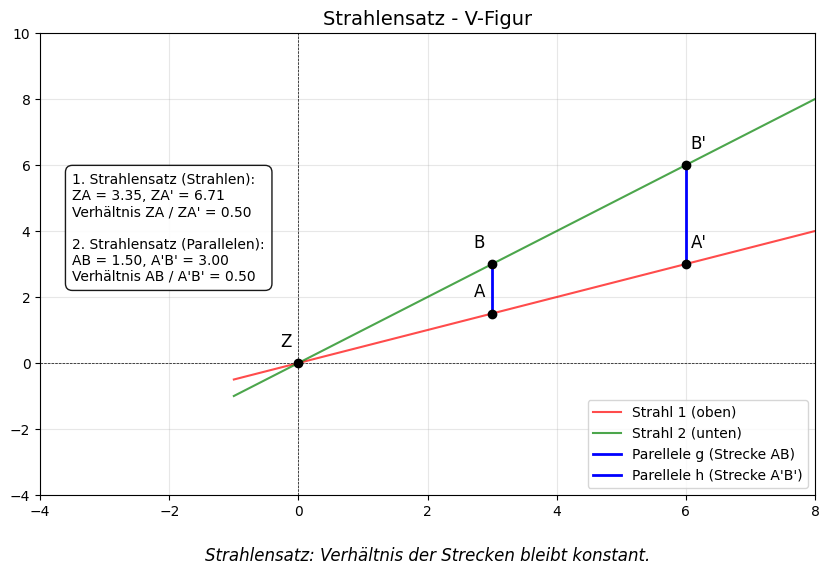

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_strahlensatz(ax, cfg, text, text_offset=(0, -6)):
    z_x, z_y = cfg["zentrum"]
    mode = cfg["modus"]

    # Definition der Parallelen-Positionen (x-Werte)
    # Bei der X-Figur muss eine Parallele links und eine rechts vom Zentrum liegen
    if mode == "V":
        g_x = z_x + cfg["distanz_g"]
        h_x = z_x + cfg["distanz_h"]
    elif mode == "X":
        g_x = z_x - cfg["distanz_g"]
        h_x = z_x + cfg["distanz_h"]
    else:
        raise ValueError("Modus muss 'V' oder 'X' sein.")

    # Punkte für Strahl 1 (oben)
    A = (g_x, z_y + cfg["steigung_strahl_1"] * (g_x - z_x))
    A_prime = (h_x, z_y + cfg["steigung_strahl_1"] * (h_x - z_x))

    # Punkte für Strahl 2 (unten)
    B = (g_x, z_y + cfg["steigung_strahl_2"] * (g_x - z_x))
    B_prime = (h_x, z_y + cfg["steigung_strahl_2"] * (h_x - z_x))

    # Zeichnen der Strahlen
    # Wir berechnen Endpunkte für den Plot, die etwas über die Parallelen hinausgehen
    plot_end_x = cfg["plot_xlim"][1] + 1
    if mode == "X":
        plot_start_x = cfg["plot_xlim"][0] - 1
    else:
        plot_start_x = z_x - 1

    x_vals = np.linspace(plot_start_x, plot_end_x, 100)
    ax.plot(x_vals, z_y + cfg["steigung_strahl_1"] * (x_vals - z_x), 'r-', label='Strahl 1 (oben)', alpha=0.7)
    ax.plot(x_vals, z_y + cfg["steigung_strahl_2"] * (x_vals - z_x), 'g-', label='Strahl 2 (unten)', alpha=0.7)

    # Zeichnen der Parallelen
    ax.plot([A[0], B[0]], [A[1], B[1]], 'b-', lw=2, label='Parellele g (Strecke AB)')
    # Parallele h (Verbindung A'-B')
    ax.plot([A_prime[0], B_prime[0]], [A_prime[1], B_prime[1]], 'b-', lw=2, label='Parellele h (Strecke A\'B\')')

    # Punkte einzeichnen
    points = {'Z': (z_x, z_y), 'A': A, 'A\'': A_prime, 'B': B, 'B\'': B_prime}
    for name, (px, py) in points.items():
        ax.plot(px, py, 'ko')
        # Textbeschriftung leicht versetzt
        offset_y = 0.5 if py >= z_y else -0.5
        offset_x = 0.2 if name in ["A'", "B'"] else -0.2
        ax.text(px + offset_x, py + offset_y, name, fontsize=12, ha='center')

    # Titel und Steup
    title_str = "V-Figur" if mode == "V" else "X-Figur"
    ax.set_title(f"Strahlensatz - {title_str}", fontsize=14)
    ax.set_xlim(cfg["plot_xlim"])
    ax.set_ylim(-4, 10)
    ax.axvline(x=z_x, color='k', linestyle='--', linewidth=0.5)  # Zentrum Z als gestrichelte Linie
    ax.axhline(y=z_y, color='k', linestyle='--', linewidth=0.5)  # Horizontale Linie durch Z
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower right')

    def dist(p1, p2):
        return np.sqrt((p1[0]-p2[0])**2 + (p1[1]-p2[1])**2)

    len_ZA = dist(points['Z'], points['A'])
    len_ZA_prime = dist(points['Z'], points["A'"])
    len_AB = dist(points['A'], points['B'])
    len_A_prime_B_prime = dist(points["A'"], points["B'"])

    # Info-Box mit Verhältnissen
    info_text = (
        f"1. Strahlensatz (Strahlen):\n"
        f"ZA = {len_ZA:.2f}, ZA' = {len_ZA_prime:.2f}\n"
        f"Verhältnis ZA / ZA' = {len_ZA / len_ZA_prime:.2f}\n\n"
        f"2. Strahlensatz (Parallelen):\n"
        f"AB = {len_AB:.2f}, A'B' = {len_A_prime_B_prime:.2f}\n"
        f"Verhältnis AB / A'B' = {len_AB / len_A_prime_B_prime:.2f}"
    )

    # Textbox platzieren
    box_x = cfg["plot_xlim"][0] + 0.5
    ax.text(box_x, 2.5, info_text, fontsize=10,
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="black", alpha=0.9))

    # Zusätzlicher Text unter dem Plot
    if text:
        ax.text(0.5 * (cfg["plot_xlim"][0] + cfg["plot_xlim"][1]), text_offset[1], text,
                ha='center', fontsize=12, style='italic')


fig, ax = plt.subplots(figsize=(10, 6))
default_text = "Strahlensatz: Verhältnis der Strecken bleibt konstant."
plot_strahlensatz(ax, Strahlensatz_cfg, default_text)
plt.show()

## 3. Anwendung: Höhenmessung (Försterdreieck)

Eine der klassischsten Anwendungen des Strahlensatzes ist die Bestimmung von Höhen, die wir nicht direkt messen können (z.B. ein Baum, ein Kirchturm oder - wie bei Thales - eine Pyramide).

**Methode "Schattenwurf":**
Wenn die Sonne scheint, werfen Objekte Schatten. Da die Sonnenstrahlen (aufgrund der großen Entfernung der Sonne) praktisch parallel auf die Erde treffen, entstehen ähnliche Dreiecke.

Wir benötigen:
1.  Einen Stab bekannter Länge (z.B. Wanderstock, $h_{Stab}$).
2.  Die Länge des Schattens dieses Stabes ($s_{Stab}$).
3.  Die Länge des Schattens des Objekts ($s_{Objekt}$).

Nach dem 2. Strahlensatz gilt:
$$ \frac{\text{Höhe Objekt}}{\text{Höhe Stab}} = \frac{\text{Schatten Objekt}}{\text{Schatten Stab}} $$

Umgestellt nach der gesuchten Höhe:
$$ \text{Höhe Objekt} = \text{Höhe Stab} \cdot \frac{\text{Schatten Objekt}}{\text{Schatten Stab}} $$

In [3]:
hoehen_rechner_cfg = {
    "h_stab": 1.5,  # Höhe des Stabs in Metern
    "s_stab": 2.0,  # Abstand des Stabs vom Punkt
    "s_objekt": 5.0,  # Abstand des Objekts vom Punkt

    # Plotting
    "plot_lim": (-1, 8)  # (x_min, x_max)
}

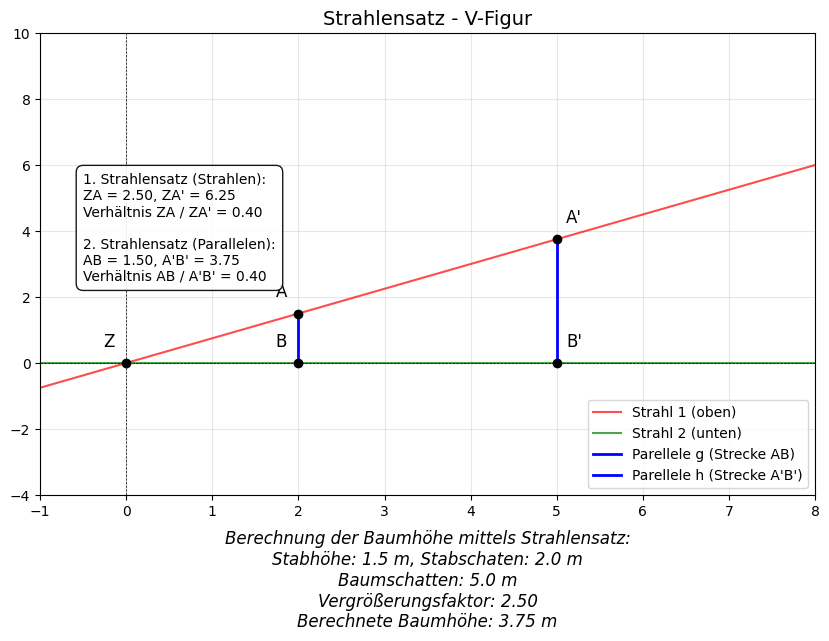

In [ ]:
# Kleiner Rechner für Strahlensatz-Aufgaben

def berechne_hoehe(stab_hoehe, stab_schatten, objekt_schatten):
    """
    Berechnet die Höhe eines Objekts basierend auf dem Strahlensatz.
    Alle Einheiten müssen gleich sein (z.B. Meter).
    """
    if stab_schatten == 0:
        return "Fehler: Schattenlänge darf nicht 0 sein."

    # Verhältnis berechnen (Skalierungsfaktor)
    faktor = objekt_schatten / stab_schatten
    objekt_hoehe = stab_hoehe * faktor

    return objekt_hoehe, faktor

# Beispiel
h_stab = hoehen_rechner_cfg["h_stab"]   # 1.50 Meter Stab
s_stab = hoehen_rechner_cfg["s_stab"]   # 2.00 Meter Schatten des Stabs
s_baum = hoehen_rechner_cfg["s_objekt"]  # 12.00 Meter Schatten des Baums

plot_lim = hoehen_rechner_cfg["plot_lim"]

hoehe, faktor = berechne_hoehe(h_stab, s_stab, s_baum)

hoehen_text = (
    f"Berechnung der Baumhöhe mittels Strahlensatz:\n"
    f"Stabhöhe: {h_stab} m, Stabschaten: {s_stab} m\n"
    f"Baumschatten: {s_baum} m\n"
    f"Vergrößerungsfaktor: {faktor:.2f}\n"
    f"Berechnete Baumhöhe: {hoehe:.2f} m"
)

hoehen_plot_cfg = {
    "modus": "V",
    "zentrum": (0, 0),
    "distanz_g": s_stab,
    "distanz_h": s_baum,
    "steigung_strahl_1": h_stab / s_stab,
    "steigung_strahl_2": hoehe / s_baum,
    "plot_xlim": (-1, max(s_baum + 2, 8)),
}

hoehen_plot_cfg = {
    "modus": "V",
    "zentrum": (0, 0),
    "distanz_g": s_stab,
    "distanz_h": s_baum,
    "steigung_strahl_1": h_stab / s_stab,
    "steigung_strahl_2": 0,  # Ground level (horizontal)
    "plot_xlim": (-1, max(s_baum + 2, 8)),
}

fig, ax = plt.subplots(figsize=(10, 6))
plot_strahlensatz(ax, hoehen_plot_cfg, hoehen_text, text_offset=(0, -8))

---

## Verständnis-Check

**Aufgabe 1: Der Fluss**
Die Breite eines Flusses soll bestimmt werden. Max steht am Ufer (Punkt A) genau gegenüber einem Baum am anderen Ufer (Punkt B). Er geht am Ufer 10 Meter nach links, steckt einen Stab in den Boden (Punkt Z), und geht weitere 2 Meter nach links (Punkt D). Dann geht er vom Ufer weg landeinwärts, bis er den Stab Z und den Baum B in einer Linie sehen (Punkt E). Er misst die Strecke vom Ufer zu Punkt E mit 3 Metern.
*Tipp:* Skizze zeichnen! Es handelt sich um eine X-Figur.
Wie breit ist der Fluss?

**Aufgabe 2: Die Kamera**
Eine Lochkamera (Camera Obscura) bildet einen 20 m hohen Turm auf der Rückwand der Kamera ab.
Die Kamera ist 30 cm lang (Abstand Loch zu Rückwand). Der Turm ist 50 m entfernt.
Wie hoch ist das Bild auf der Rückwand?

### Lösungen

<details><summary>Lösung Aufgabe 1</summary>

Dies ist eine Anwendung des 2. Strahlensatzes an der X-Figur.
- Strecke am Ufer "klein" (D bis Z) = 2 m
- Strecke am Ufer "groß" (A bis Z) = 10 m
- Strecke landeinwärts (D bis E) = 3 m
- Gesuchte Breite (A bis B) = $x$

Verhältnis: $\frac{x}{3m} = \frac{10m}{2m}$
$x = 3m \cdot 5 = 15m$.
Der Fluss ist 15 Meter breit.

</details>

<details><summary>Lösung Aufgabe 2</summary>

Auch hier liegt eine X-Figur vor (die Lichtstrahlen kreuzen sich im Loch der Kamera).
- Höhe Objekt $H = 20$ m
- Entfernung Objekt $d_1 = 50$ m
- Entfernung Bild $d_2 = 0.30$ m (30 cm)
- Gesuchte Bildhöhe $h = ?$

Verhältnis: $\frac{h}{H} = \frac{d_2}{d_1}$
$h = 20m \cdot \frac{0.30m}{50m} = 20 \cdot 0.006 = 0.12$ m.
Das Bild ist 12 cm hoch.

</details>

## Zusammenfassung

| Thema | Kernaussage |
|-------|-------------|
| V-Figur | Zwei Strahlen vom Zentrum, geschnitten von parallelen Geraden; Dreiecke sind ähnlich |
| X-Figur | Zentrum zwischen den Parallelen (Sanduhr); gleiche Verhältnisse wie V-Figur |
| 1. Strahlensatz | Verhältnisse der Abschnitte auf den Strahlen sind gleich |
| 2. Strahlensatz | Verhältnis der Parallelen-Abschnitte = Verhältnis der Strahlen-Abschnitte |
| Höhenmessung | Mit Schattenwurf und bekannter Stablänge unzugängliche Höhen berechnen |



---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Strahlensatz | Intercept Theorem / Basic Proportionality Theorem |
| Strahl | Ray |
| Parallele | Parallel line |
| Zentrum | Center / Origin |
| Verhältnis | Ratio |
| Abschnitt / Strecke | Segment |
| V-Figur | V-Figure (Triangles on the same side) |
| X-Figur | X-Figure (Bowtie / Hourglass shape) |
| Schatten | Shadow |
| Messen | To measure |